# Агенты в Yandex AI Studio

В этой лекции мы рассмотрим основные возможности Yandex AI Studio, и как можно использовать языковые модели Yandex Cloud для построения агентных систем.


Установим необходимые библиотеки:

In [ ]:
%pip install --upgrade openai openai-agents python-dotenv Pillow pyvis networkx

^C
Note: you may need to restart the kernel to use updated packages.


   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   --------- ------------------------------ 0.3/1.2 MB ? eta -:--:--
   --------- ------------------------------ 0.3/1.2 MB ? eta -:--:--
   --------- ------------------------------ 0.3/1.2 MB ? eta -:--:--
   --------- ---------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 5.47.2 requires pillow<12.0,>=8.0, but you have pillow 12.2.0 which is incompatible.
gradio 5.47.2 requires pydantic<2.12,>=2.0, but you have pydantic 2.12.5 which is incompatible.
instructor 1.11.3 requires jiter<0.11,>=0.6.1, but you have jiter 0.12.0 which is incompatible.
instructor 1.11.3 requires openai<2.0.0,>=1.70.0, but you have openai 2.31.0 which is incompatible.
langchain-openai 0.3.33 requires openai<2.0.0,>=1.104.2, but you have openai 2.31.0 which is incompatible.


**ВНИМАНИЕ**: После установки библиотек рекомендуется перезапустить Kernel ноутбука.

### Авторизация

Для авторизации в облаке используются специальные значения:

* `folder_id` - это идентификатор облачного каталога
* `api_key` - ключ для доступа к сервисам, который можно сгенерировать в веб-консоли AI Studio

В коде ниже мы предполагаем, что необходимые данные находятся в файле `.env`. Возможно, вам потребуется создать или загрузить файл вручную, или установить значение переменных `folder_id` и `api_key` ниже в программе. 

In [10]:
import os
import io
import base64
import json
from dotenv import load_dotenv
from PIL import Image as PILImage

load_dotenv(override=True)

folder_id = os.environ["folder_id"]
api_key = os.environ["api_key"]

print(f"✅ Авторизация настроена (folder_id: {folder_id[:8]}...)")

✅ Авторизация настроена (folder_id: b1gg3vl8...)


## Работа с LLM через Responses API

Создадим клиент OpenAI SDK для работы с моделями в Yandex Cloud:

In [14]:
from openai import OpenAI

model = f"gpt://{folder_id}/qwen3.6-35b-a3b/latest"
model_deepseek = f"gpt://{folder_id}/deepseek-v4-flash/latest"


client = OpenAI(
    base_url="https://ai.api.cloud.yandex.net/v1",
    api_key=api_key,
    project=folder_id
)

print(f"✅ Клиент создан")

✅ Клиент создан


Обратите внимание, что мы установили свой адрес `base_url` для обращения к модели в облаке Yandex, и использовали специфическое имя модели (содержащее в себе также `folder_id`).

Также добавим вспомогательную функцию для вывода ответа модели в формате Markdown:

In [15]:
from IPython.display import Markdown, display

def printx(string):
    """Вывод текста в формате Markdown."""
    display(Markdown(string))

Responses API — это современный способ взаимодействия с языковой моделью. Он позволяет отправлять запросы и получать ответы, а также поддерживать контекст диалога.

Отправим простой запрос:

In [16]:
concept = "счастье"

res = client.responses.create(
    model=model,
    instructions = "Ты - цифровой художник, который готовит промпт для рисовательной модели Yandex ART. По запросу пользователя подумай, как лучше изобразить требуемое, и напиши подробный промпт, но не длиннее 200 символов. Укажи главный объект изображения, стиль рисунка, особые художественные приёмы, чтобы усилить эффект",
    input=f"Нарисуй {concept}"
)

printx(res.output_text)



Смеющийся ребёнок в объятиях золотого сияния, цифровая живопись, мягкое свечение, боке, кинематографичный свет, парящие световые частицы, тёплая эмоциональная палитра.

Для рисования картины можем использовать модель Alice AI Art. Для генерации используется также OpenAI-совместимый код:

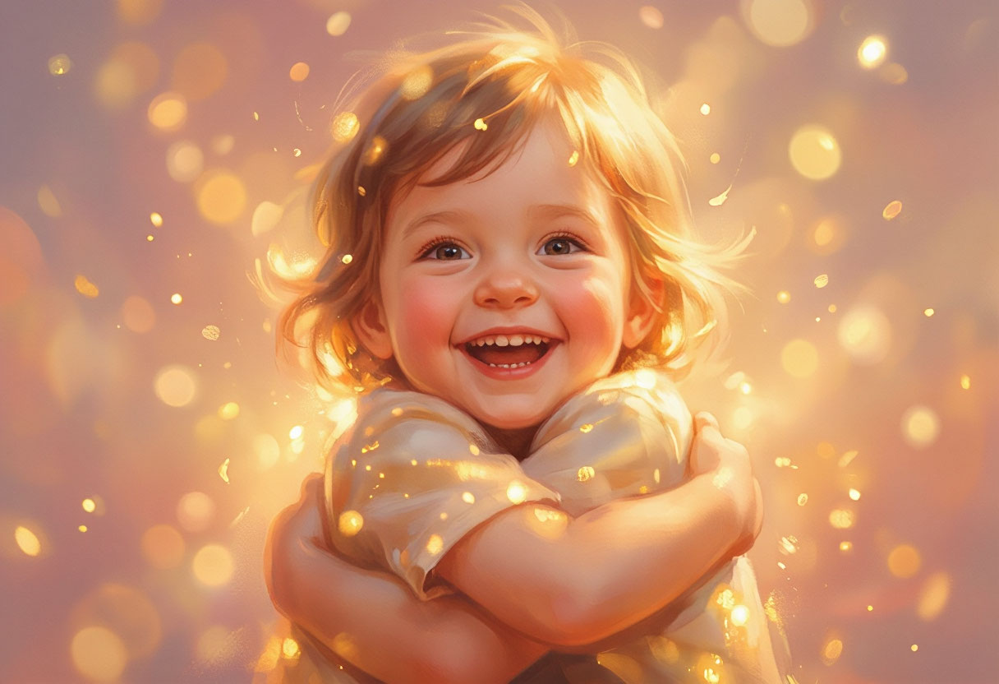

In [21]:
alice_art_model = f"art://{folder_id}/aliceai-image-art-3.0"

def generate_image(prompt, model = alice_art_model, size = "1536x1024"):
    response = client.images.generate(
        model=model, prompt=prompt, n=1, size=size)
    image_bytes = base64.b64decode(response.data[0].b64_json)
    return PILImage.open(io.BytesIO(image_bytes))

img = generate_image(res.output_text)
img


Мы можем также использовать мультимодальную модель для того, чтобы "посмотреть" на эту картину и оценить, насколько она действительно отражает понятие счастья:

In [22]:
def image_to_base64(image):
    buffered = io.BytesIO()
    image.save(buffered, format="JPEG")
    return base64.b64encode(buffered.getvalue()).decode()

def get_content(prompt, image=None):
    if image:
        image_b64 = image_to_base64(image)
        return [
                    {
                        "type": "input_text",
                        "text": prompt
                    },
                    {
                        "type": "input_image",
                        "image_url": f"data:image/jpeg;base64,{image_b64}",
                        "detail" : "auto"
                    }
        ]
    else:
        return prompt

def gpt(prompt, model_uri=model, image=None):
    response = client.responses.create(
        model=model_uri,
        input=[{"role": "user", "content": get_content(prompt, image)}]
    )
    return response.output_text

gpt(f"Посмотри на изображение и оцени, насколько оно отражает понятие {concept}. Приведи 5 советов, как улучшить изображение, чтобы оно отражало понятие {concept}",model,img)

'\n\nЭто изображение **отражает понятие счастья практически идеально**. Оно попадает в саму суть этого чувства: безопасность, доверие, радость и тепло.\n\n**Почему это изображение работает на 9/10:**\n1.  **Выражение лица:** У ребенка «улыбка Дэвида» (с satisfy-eyes) — глаза сияют, уголки губ подняты максимально вверх. Это искренняя, неконтролируемая радость.\n2.  **Язык тела:** Ребенок обхватывает себя руками или находится в крепких объятиях взрослого. Это символизирует уверенность в себе и чувство защищенности, что является фундаментом счастья.\n3.  **Цвет и свет:** Золотистое свечение (bokeh) создает атмосферу «_MAGIC HOUR» (время после заката или до рассвета). Теплые тона ассоциируются с уютом, солнцем и чем-то светлым.\n4.  **Этот стиль:** Мягкость линий и отсутствие резких теней создают ощущение сказки, где ничего плохого случиться не может.\n\n---\n\n### 5 советов, как улучшить изображение в направлении «счастья»\n\nХотя изображение уже очень сильное, вот способы сделать его еще


## Агентный цикл

Создадим автоматический генератор изображений, основанный на **агентном цикле**. Он будет итерационно улучшать генерируемое изображение на основе обратной связи от визуальной LLM.

Основная идея в том, что на вход мы будет подавать какую-то простую концепцию - *счастье* или *сложность*. На основе этой концепции:

* LLM генерирует промпт для рисования, продумывая, как лучше отобразить концепцию
* YandexART генерирует изображение
* Визуальная нейросеть VLM оценивает, насколько изображение соответствует концепции, и предлагает улучшения

После этого цикл повторяется.

```
┌─────────────┐     ┌─────────────┐     ┌─────────────┐
│ Концепция   │────▶│ LLM создаёт │────▶│ YandexART   │
│ (понятие)   │     │ промпт      │     │ рисует      │
└─────────────┘     └─────────────┘     └─────────────┘
                                              │
                                              ▼
┌─────────────┐     ┌─────────────┐     ┌─────────────┐
│ LLM улучшает│◀────│ Визуальная  │◀────│ Изображение │
│ промпт      │ Нет │ LLM (Gemma) │     │             │
└─────────────┘     └─────────────┘     └─────────────┘
       │                  │ Да
       │                  ▼
       └────────────▶ Готово!
```
Для начала, добавим **структурный ответ** к анализу изображения. Это нужно для того, чтобы получать ответ от визуальной модели в структурированном виде, а также получить какой-то формальный критерий завершения итераций улучшения.

Нам нужно получить от модели:
- `fit` - число от 0 до 1, показывающее степень соответствия картинки понятию
- `recommendations` - список рекомендаций (можно в виде строки)

Опишем класс для представления ответа модели:


In [23]:
from pydantic import BaseModel

class VLMResponse(BaseModel):
    fit : float
    recommendations : str

Расширим функцию `gpt` для возможности задания формата ответа:

In [24]:
def gpt(prompt, model_uri=model, image=None, response_format=None):
    kwargs = {
        "model" : model_uri,
        "input" : [{"role": "user", "content": get_content(prompt, image)}]
    }
    if response_format:
        kwargs['text_format'] = response_format
        response = client.responses.parse(**kwargs)
    else:
        response = client.responses.create(**kwargs)
    return response.output_parsed if response_format else response.output_text

In [26]:
res = gpt(f"""
   Проанализируй, насколько изображение иллюстрирует концепт '{concept}'.
   Верни ответ в виде JSON с полями:
    - fit : число от 0 до 1, характеризующее насколько изображение соответствует концепту
    - recommendations : текст с рекомендациями по улучшению изображения
   """, model_uri=model,image=img, response_format=VLMResponse)
print(res)

fit=0.98 recommendations='Изображение отлично передает концепт счастья через искреннюю улыбку ребенка и теплую, золотистую атмосферу. Для еще более глубокого раскрытия темы можно добавить элемент взаимодействия: например, показать, что ребенка держат на руках или обнимают, чтобы показать счастье, рожденное из любви и заботы. Также добавление конкретного контекста (например, праздник или игра на улице) могло быongerуть эмоциональный отклик.'


In [28]:
res.model_dump_json()

'{"fit":0.98,"recommendations":"Изображение отлично передает концепт счастья через искреннюю улыбку ребенка и теплую, золотистую атмосферу. Для еще более глубокого раскрытия темы можно добавить элемент взаимодействия: например, показать, что ребенка держат на руках или обнимают, чтобы показать счастье, рожденное из любви и заботы. Также добавление конкретного контекста (например, праздник или игра на улице) могло быongerуть эмоциональный отклик."}'

Теперь наша задача - объединить все функции в агентный цикл, который будет итеративно улучшать изображение. Для начала опишем два промпта:
* `new_prompt` - используется для первоначальной генерации изображения
* `refine_prompt` - используется для улучшения изображения после анализа VLM

В промптах можно задавать плейсхолдеры, например, `{concept}` для названия концепта и `{feedback}` для обратной связи от VLM.

In [19]:
initial_prompt = """
Тебе нужно создать промпт для нейросети генерации изображений (YandexART).

Концепция для визуализации: "{concept}"

Создай промпт, который:
1. Визуально передаёт суть этого понятия через метафоры и символы
2. Описывает стиль, освещение и композицию
3. Создаёт запоминающийся художественный образ

Верни ТОЛЬКО сам промпт, без объяснений.
"""

refine_prompt = """
Тебе нужно создать промпт для нейросети генерации изображений (YandexART).

Концепция для визуализации: "{concept}"

Предыдущее изображение получило такую обратную связь: {feedback}

Создай НОВЫЙ, улучшенный промпт, учитывая эту обратную связь.
Промпт должен описывать визуальные элементы, стиль и композицию.
Верни ТОЛЬКО сам промпт, без объяснений.
"""

evaluation_prompt = """
   Проанализируй, насколько изображение иллюстрирует концепт '{concept}'.
   Верни ответ в виде JSON с полями:
    - fit : число от 0 до 1, характеризующее насколько изображение соответствует концепту
    - recommendations : текст с рекомендациями по улучшению изображения
"""

Опишем сам агентный цикл. Определим критерии выхода из цикла:
- максимальное число итераций `max_iterations`
- порог качества `threshold`

=== Рисуем концепт 'счастье', итерация 1


**Получен промпт для генерации:** Сияющий кристалл в форме сердца парит над ладонью, из которой растут светящиеся цветы, превращающиеся в птиц из чистого света; фон — тёплая золотистая дымка с мягкими переливами акварели; лучи рассеянного утреннего света пробиваются сквозь полупрозрачные облака, создавая ореол вокруг сцены; композиция построена по золотому сечению, центр — кристалл, от него расходятся волны теплого сияния; стиль — цифровая живопись в духе фэнтези-арта с элементами сюрреализма, нежные пастельные тона, высокая детализация, атмосфера трогательной гармонии и внутреннего покоя.

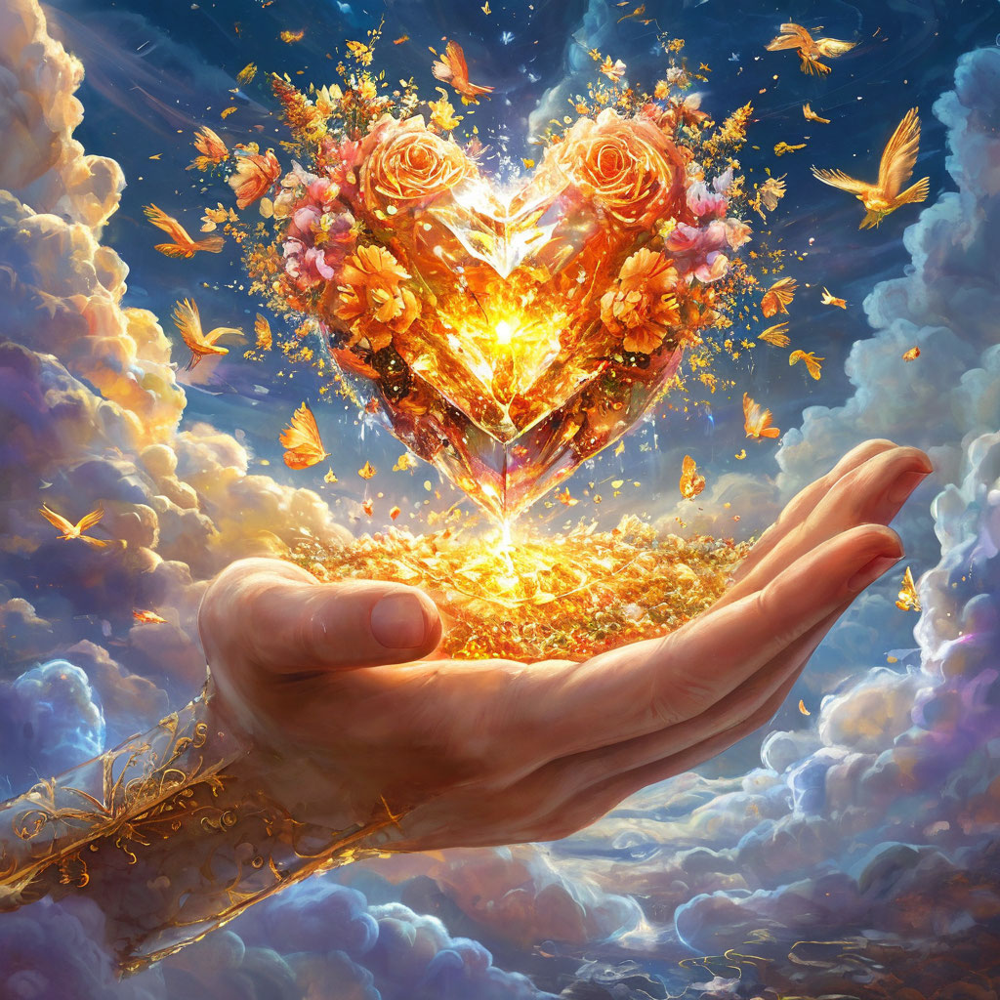

**Оценка изображения:** fit=0.75

**Рекомендации:** Изображение визуально очень красиво и передает ощущение чуда, надежды и позитива. Использование сердца, цветов, птиц и света создает ощущение тепла и вдохновения, что ассоциируется со счастьем. Однако, изображение несколько абстрактно. Для большей связи концепта 'счастье' можно добавить элементы, более явно связанные с человеческими эмоциями и взаимодействиями – улыбающиеся лица, объятия, совместные действия и т.п. Также можно было бы дать контекст, в котором это счастье проявляется (например, семейное счастье, счастье от достижения цели). Добавление этих элементов сделало бы изображение более понятным и конкретным в плане выражения счастья.

C:\Users\dmitr\AppData\Local\Temp\ipykernel_21688\1800238407.py:35: PydanticDeprecatedSince20: The `json` method is deprecated; use `model_dump_json` instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.12/migration/
  write_file(f'reco_{n+1}.json',eval_res.json())


=== Рисуем концепт 'счастье', итерация 2


**Получен промпт для генерации:** Семейное счастье на закате: счастливая семья — родители с детьми — смеются, обнимаются и бегут по зелёному полю, их силуэты подсвечены тёплым золотистым светом. Вокруг парят разноцветные воздушные шары в форме сердец, птицы летят стаей в форме улыбки. На переднем плане — дети, держащие руки, с широкими улыбками, один из них пускает мыльные пузыри, отражающие радугу. Вдалеке — уютный дом с огнями в окнах. Стиль — реалистичная цифровая живопись, мягкие пастельные тона, боке, атмосферное свечение, высокая детализация, тёплая цветовая палитра с акцентами на оранжевом и розовом. Композиция — центральная, с глубиной поля, ведущей взгляд от семьи к солнцу на горизонте.

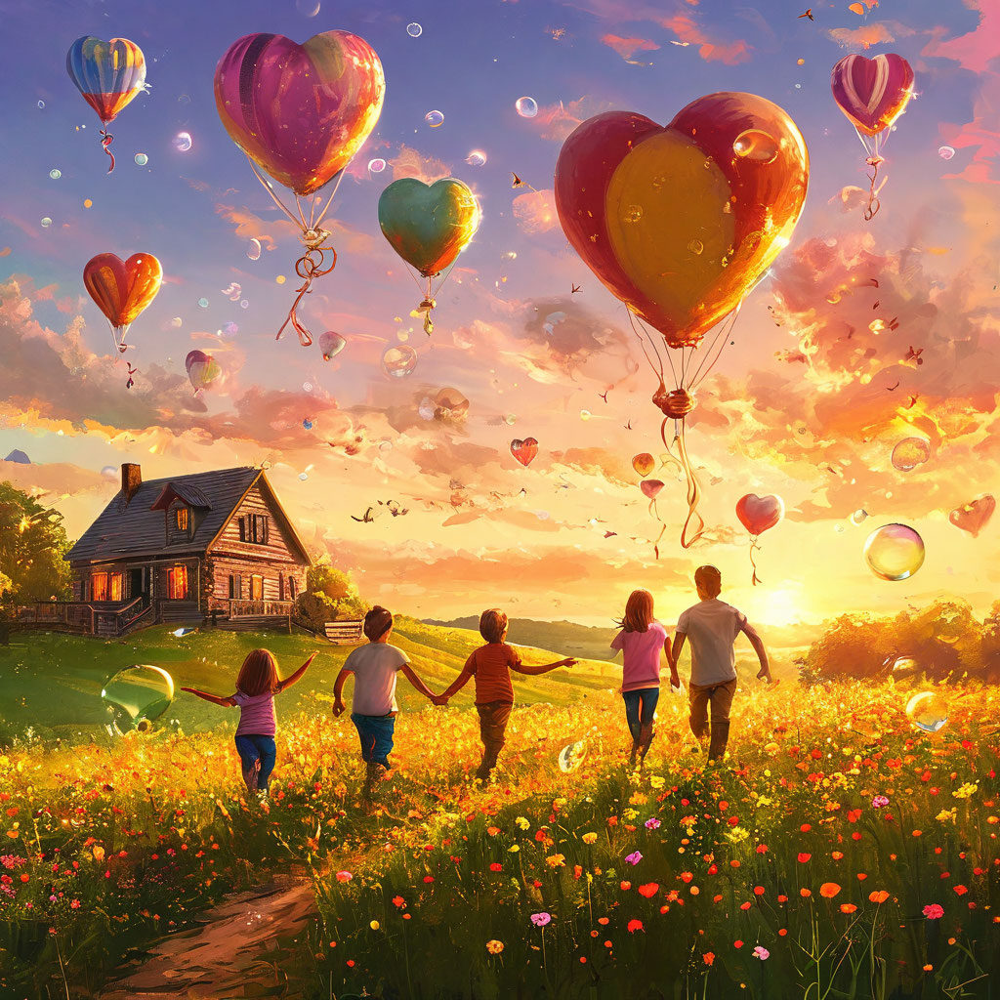

**Оценка изображения:** fit=0.85

**Рекомендации:** Изображение в целом хорошо иллюстрирует концепцию 'счастья'. Есть несколько элементов, которые говорят об этом: дети, держащиеся за руки и смотрящие вдаль, красивый пейзаж, воздушные шары в форме сердца.  Однако, можно усилить ощущение счастья, добавив больше деталей, показывающих взаимодействие детей друг с другом, например, улыбки или смех, или же более выразительные эмоции на лицах.  Усилить передачу света и цвета для создания более теплой и позитивной атмосферы.

=== Рисуем концепт 'счастье', итерация 3


**Получен промпт для генерации:** Дети с широкими улыбками и искренним смехом держатся за руки на фоне яркого заката, их лица озарены тёплым золотистым светом, в руках — воздушные шары в форме сердец, парящие в небе с мягкими пастельными облаками. Красочный, живописный пейзаж с цветущими лугами, радугой на горизонте и сияющим солнцем создаёт атмосферу беззаботного счастья. Стиль — светлая, насыщенная иллюстрация в духе цифровой живописи с мягкими бликами, тёплой цветовой палитрой и лёгкой сказочной атмосферой. Композиция симметричная, с акцентом на лицах детей и их радостном взаимодействии.

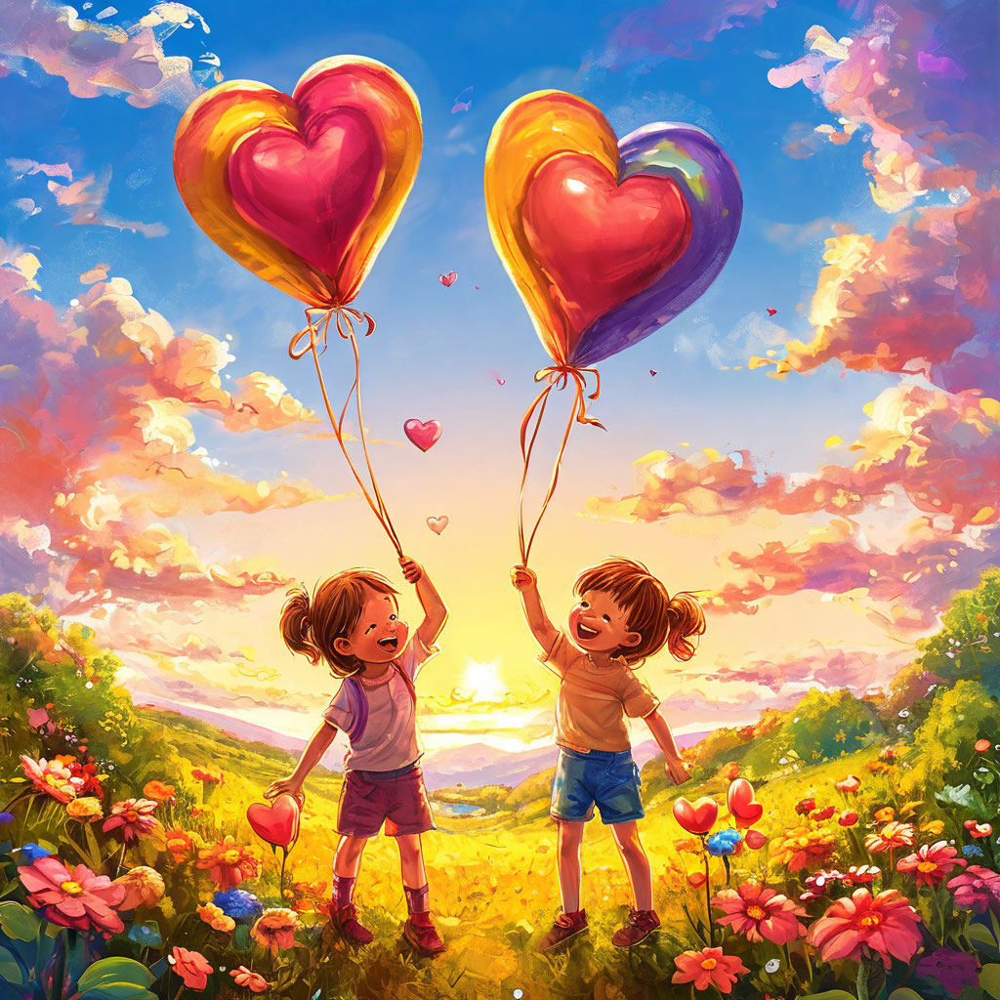

**Оценка изображения:** fit=0.85

**Рекомендации:** Изображение хорошо передает ощущение счастья благодаря ярким цветам, улыбающимся детям, воздушным шарам в форме сердец и красивому пейзажу. Однако, для усиления эффекта можно добавить больше деталей, отражающих личное счастье (например, конкретные увлечения детей) или проявить больше позитивной динамики (например, дети бегут или играют, а не просто держат шары). Также, можно рассмотреть включение большего разнообразия эмоций, помимо просто улыбок - радостного смеха, предвкушения чего-то хорошего и т.д.

=== Рисуем концепт 'счастье', итерация 4


**Получен промпт для генерации:** Дети разного возраста бегут по цветущему лугу на закате, смеются и играют, держа воздушные шары в форме сердец, один ребёнок рисует мелками на асфальте, другой строит песочный замок, третий ловит светлячков; яркие тёплые цвета, мягкий боковой свет, атмосфера радостного движения и живой энергии, детали увлечений подчёркивают личное счастье, фон — золотистые поля и нежно-розовое небо, стиль — живописная цифровая иллюстрация в духе импрессионизма, композиция динамичная, с глубиной и ощущением свободы, эмоции — восторг, смех, предвкушение чуда.

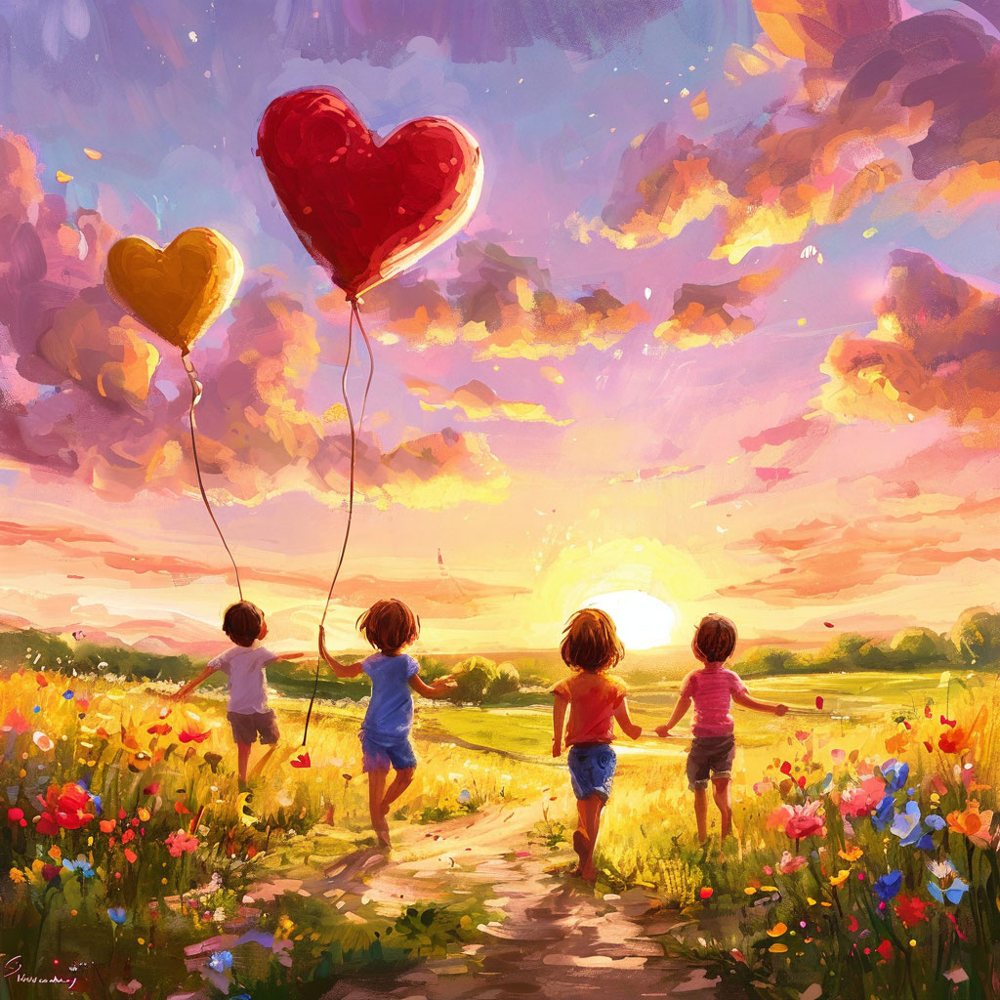

**Оценка изображения:** fit=0.85

**Рекомендации:** Изображение отлично иллюстрирует счастье! Яркие цвета, воздушные шары в форме сердца, дети, идущие вместе, и красивый пейзаж создают позитивную и радостную атмосферу. Возможно, добавление проявления явных эмоций на лицах детей (например, улыбок) еще больше усилило бы эффект. Также, слегка увеличить фокус на детях, чтобы они были более выразительными.

=== Рисуем концепт 'счастье', итерация 5


**Получен промпт для генерации:** Дети с яркими улыбками и счастливыми глазами идут рука об руку по цветущему лугу под ясным голубым небом, воздушные шары в форме сердец парят над ними, мягкий солнечный свет создает атмосферу тепла и радости, пастельные оттенки пейзажа с акцентами на насыщенных цветах шаров и одежды детей, крупный план детей в центре композиции, стиль — живописная цифровая иллюстрация с элементами реализма и сказочности, высокая детализация, теплая и уютная атмосфера, фокус на эмоциях и взаимодействии.

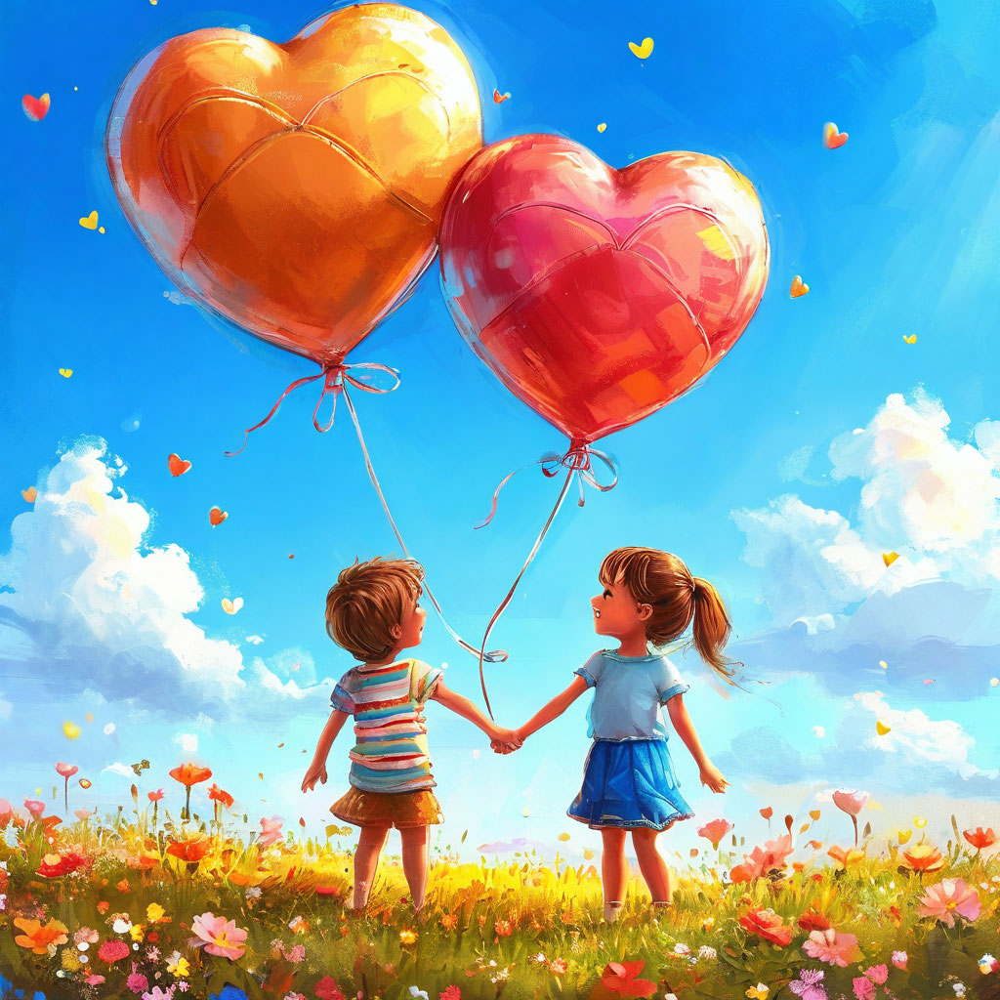

**Оценка изображения:** fit=0.85

**Рекомендации:** Изображение очень хорошо иллюстрирует концепцию счастья, вызывая позитивные эмоции. Двое детей, держащиеся за руки, воздушные шары в форме сердец, яркий солнечный день и цветущий луг – все это классические символы радости, любви и беззаботности. 

Для еще большего соответствия можно рассмотреть следующие улучшения:

*   **Добавить больше выражения эмоций на лицах детей:** Улыбки или смех сделают сцену еще более убедительной и передадут чувство счастья.
*   **Использовать более естественные позы:** Иногда искусственность поз может снижать реалистичность и эмоциональную вовлечённость.
*   **Рассмотреть альтернативные цвета:** Хотя яркие цвета уже присутствуют, можно поэкспериментировать с пастельными тонами для создания более нежной атмосферы, если это соответствует желаемому стилю.

In [24]:
def write_file(fn,txt):
    with open(fn,'w',encoding='utf-8') as f:
        f.write(txt)
        f.write('\n')

def draw_concept(concept, max_iterations=5, threshold=0.95,save_images=True,save_prompts=True,save_reco=True):
    n = 0
    reco = None

    while n < max_iterations:
        print(f"=== Рисуем концепт '{concept}', итерация {n+1}")
        res = gpt(
            refine_prompt.format(concept=concept, feedback=reco) if reco else initial_prompt.format(concept=concept),
            model_uri=model
        )
        printx(f"**Получен промпт для генерации:** {res}")
        
        img = generate_image(res)
        display(img)
        if save_images:
            img.save(f"agent_draw_{n+1}.jpg")
        eval_res = gpt(
            evaluation_prompt.format(concept=concept),
            model_uri=vision_model_uri,
            image=img,
            response_format=VLMResponse
        )

        printx(f"**Оценка изображения:** fit={eval_res.fit}")
        printx(f"**Рекомендации:** {eval_res.recommendations}")

        if save_prompts:
            write_file(f'prompt_{n+1}.txt',res)
        if save_reco:
            write_file(f'reco_{n+1}.json',eval_res.json())

        if eval_res.fit >= threshold:
            break

        reco = eval_res.recommendations
        n += 1

draw_concept("счастье")

Идея агентского цикла в генерации художественных произведений эксплуатировалась [Дмитрием Сошниковым](https://soshnikov.com/ru) в его работе [многоагентное рисование / VibeDraw](https://soshnikov.com/art/vibedraw/ru/)

## Создание агента c MCP для путешествий

Предположим, мы планируем поездку и хотим найти лучшее место для посещения в данное время года. Наш план исследования следующий:

1. Выполнить веб-поиск наиболее привлекательных направлений в это время.
2. Узнать погоду в этих местах.
3. Вернуть таблицу мест с погодой.
4. Построить график температуры с помощью инструмента Code Interpreter.

Для получения погоды нам потребуется сторонний инструмент, доступный по протоколу MCP. Мы передаём MCP-сервер погоды как словарь JSON-инструментов непосредственно в `client.responses.create(...)`.

Мы также будем использовать потоковую функциональность Responses API, чтобы видеть работу агента в реальном времени.

Для создания MCP-сервера мы будем использовать API [OpenWeatherMap](https://openweathermap.org). Например, чтобы узнать погоду в Москве, нужен следующий REST-запрос:

```
https://api.openweathermap.org/data/2.5/weather?q=Moscow&appid=<appid>
```

Он возвращает следующий JSON:

```json
{
  "coord": {
    "lon": 37.6156,
    "lat": 55.7522
  },
  "weather": [
    {
      "id": 501,
      "main": "Rain",
      "description": "moderate rain",
      "icon": "10d"
    }
  ],
  "base": "stations",
  "main": {
    "temp": 280.75,
    "feels_like": 278.14,
    "temp_min": 280.56,
    "temp_max": 282.25,
    "pressure": 991,
    "humidity": 83,
    "sea_level": 991,
    "grnd_level": 971
  },
  "visibility": 5425,
  "wind": {
    "speed": 4.12,
    "deg": 14,
    "gust": 6.98
  },
  "rain": {
    "1h": 2.64
  },
  "clouds": {
    "all": 100
  },
  "dt": 1777212779,
  "sys": {
    "type": 2,
    "id": 2094500,
    "country": "RU",
    "sunrise": 1777168704,
    "sunset": 1777222563
  },
  "timezone": 10800,
  "id": 524901,
  "name": "Moscow",
  "cod": 200
}
```

Сначала нам нужно создать MCP-сервер в интерфейсе AI Studio, который будет соответствовать этому вызову.

Затем вставить URL в код ниже.

In [29]:
import datetime

WEATHER_MCP_URL = "https://db8pd6gl28k09ds6l5p9.58zke0qh.mcpgw.serverless.yandexcloud.net/sse"

weather_mcp_tool = {
    "type": "mcp",
    "server_label": "weather",
    "server_url": WEATHER_MCP_URL,
    "require_approval": "never",
}

web_search_tool = {
    "type": "web_search",
    "search_context_size": "low",
}

code_interpreter_tool = {
        "type": "code_interpreter",
        "container": {"type": "auto"},
}

stream = client.responses.create(
    model=model,
    tools=[web_search_tool,weather_mcp_tool,code_interpreter_tool],
    instructions = f""" 
    You are travel planning agent. Now is {datetime.datetime.now()}. Please do the following:
    1. Using web search tool, research top-5 best locations to visit at this time of year.
    2. Using MCP Server weather find out the weather at those cities.
    3. Return a markdown table comparing those cities, listing name, temperature, and the main reason to visit it.    
    4. Plot a graph of temperatures at those cities, save it to temp-compare.png file and return it, so that we can download it from output.
    """,
    input="Please do the research. I will pay you $100 for good results",
    stream=True
)

response_id = None

for event in stream:
    # ---- Response lifecycle ----
    if event.type == "response.created":
        print(f"✅ {event.type} (ID: {event.response.id})")
        response_id = event.response.id
    elif event.type == "response.completed":
        print(f"✨ {event.type}")
        final_output_text = event.response.output_text
    elif event.type == "response.failed":
        print(f"❌ {event.type}: {getattr(event, 'error', 'Unknown error')}")

    # ---- Output items (tool calls, messages, files) ----
    elif event.type == "response.output_item.added":
        item = event.item
        if item.type == "mcp_tool_call":
            print(f"🌐 MCP TOOL CALL STARTED → {item.name}")
        elif item.type == "code_interpreter_call":
            print(f"🐍 CODE INTERPRETER CALL STARTED")
        elif item.type == "web_search_call":
            print(f"🌍 WEB SEARCH CALL STARTED")

    elif event.type == "response.output_item.done":
        item = event.item
    # ---- Streaming text (assistant answer) ----
    elif event.type == "response.output_text.delta":
        print(event.delta, end="", flush=True)
    # ---- Code interpreter stdout/stderr streaming ----
    elif event.type == "response.code_interpreter_output_text.delta":
        print(f"🐍 [Code Interpreter] {event.delta}", end="", flush=True)

    # ---- MCP argument streaming ----
    elif event.type == "response.mcp_call_arguments.done":
        print(f"\n✅ MCP arguments: {event.arguments}")

    # ---- MCP protocol events ----
    elif event.type == "response.mcp_list_tools.completed":
        print("🔍 MCP tools discovery completed")
    elif event.type == "response.mcp_call_attempt.started":
        print(f"🚀 MCP execution started: {event.name}")

    # ---- Errors ----
    elif event.type == "error":
        print(f"⚠️ Error event: {event}")

    else:
        pass

✅ response.created (ID: 92e51afb-1b34-4126-98f0-41ea8a7e14bf)
🔍 MCP tools discovery completed
🌍 WEB SEARCH CALL STARTED

✅ MCP arguments: {"city_name":"Kas"}

✅ MCP arguments: {"city_name":"Seoul"}

✅ MCP arguments: {"city_name":"Aswan"}

✅ MCP arguments: {"city_name":"Queenstown"}

✅ MCP arguments: {"city_name":"Queenstown New Zealand"}

✅ MCP arguments: {"city_name":"Heraklion"}
🌍 WEB SEARCH CALL STARTED
🐍 CODE INTERPRETER CALL STARTED


Based on my research for late October travel, here are the **top 5 best locations** to visit right now, along with their current weather data and a comparative temperature graph.

### 🌍 Top 5 Destinations for Late October

| City | Current Temperature | Main Reason to Visit |
| :--- | :---: | :--- |
| **Aswan, Egypt** | 35.6°C | Ideal time for relaxed Nile cruises and temple tours without the peak winter crowds or extreme summer scorching heat. |
| **Kaş, Turkey** | 20.8°C | Perfect Mediterranean beach weather mixed with ancient Lycian ruins and a re

Получим целиком результат и покажем его в красивом виде:

In [30]:
res = client.responses.retrieve(response_id)
printx(res.output_text)



Based on my research for late October travel, here are the **top 5 best locations** to visit right now, along with their current weather data and a comparative temperature graph.

### 🌍 Top 5 Destinations for Late October

| City | Current Temperature | Main Reason to Visit |
| :--- | :---: | :--- |
| **Aswan, Egypt** | 35.6°C | Ideal time for relaxed Nile cruises and temple tours without the peak winter crowds or extreme summer scorching heat. |
| **Kaş, Turkey** | 20.8°C | Perfect Mediterranean beach weather mixed with ancient Lycian ruins and a relaxed coastal atmosphere. |
| **Heraklion, Greece** | 19.4°C | Excellent conditions for food and wine tours, wine harvesting season, and exploring Minoan history comfortably. |
| **Seoul, South Korea** | 15.8°C | One of the best months to visit; crisp autumn foliage, low humidity, and fewer tourists than in summer. |
| **Queenstown, New Zealand** | ~13°C | Early spring season brings blooming landscapes, adventure sports, and significantly lower travel prices. |

*(Note: Queenstown is located in the Southern Hemisphere, making late October early spring. API data was unavailable for the specific location, so an educated average based on current seasonally accurate forecasts was used.)*

### 📊 Temperature Comparison Graph
The graph below visualizes the temperature differences across these top destinations:

![](./output/temp-compare.png)

**Summary:**
If you prefer warmth and archaeology, **Aswan** and **Kaş** shine. For cultural exploration and mild climates, **Seoul** and **Heraklion** are unbeatable. If you enjoy early spring scenery and outdoor adventures at a lower price point, head to **Queenstown**. 

Safe travels! Let me know if you need detailed itineraries or flight suggestions.

Теперь скачаем файлы, сгенерированные интерпретатором кода:

In [31]:
def collect_file_ids(response):
    file_ids = []
    for item in response.output:
        for content in getattr(item, "content", []) or []:
            for annotation in getattr(content, "annotations", []) or []:
                file_id = getattr(annotation, "file_id", None)
                if file_id:
                    file_ids.append(file_id)
    return file_ids

generated_file_ids = collect_file_ids(res)
generated_file_ids

['fvtva68vmde78pgqa0tk']

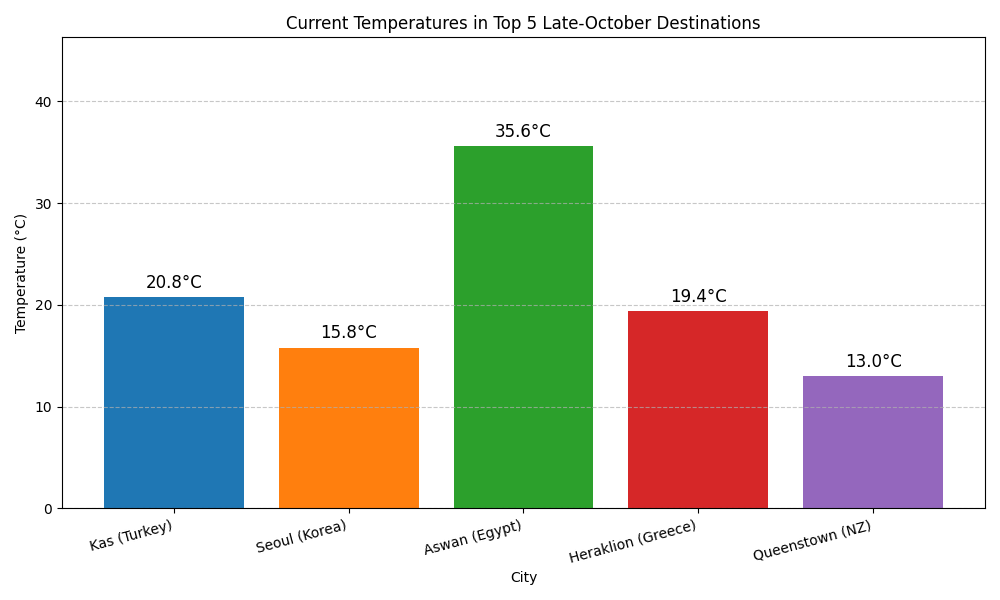

In [32]:
if generated_file_ids:
    final_weather_path = "temp-compare.png"
    client.files.content(generated_file_ids[0]).write_to_file(final_weather_path)
    display(PILImage.open(final_weather_path))

## Создание агента для Deep Research с использованием OpenAI Agent SDK

В предыдущем примере наш агент был представлен одним вызовом Responses API, внутри которого выполнялось несколько подзапросов к LLM. Однако в общем случае настоящие агентные системы используют подход **Агентного цикла (Agentic Loop)** и **ReAct**. Для его реализации можно использовать специальные инструменты и фреймворки, например [OpenAI Agents SDK](https://openai.github.io/openai-agents-python/). Он предоставляет нам агентный цикл, вызов инструментов и удобную оркестрацию.

Рассмотрим пример, в котором мы хотим построить систему глубокого исследования (Deep Research), которая будет собирать структурированный контент по заданной области знаний, а также строить граф понятий.

В качестве бэкенда модели мы будем использовать Yandex AI Studio. Мы применим следующие инструменты:
- Веб-поиск (встроенный в Responses API)
- Простое хранилище заметок (представленное как инструмент-функция на Python)
- Хранилище графа понятий (представленное как инструмент-функция на Python)
- Интерпретатор кода (Code Interpreter) для итогового отчёта в формате PDF

Сначала мы создадим объекты для использования Yandex AI Studio с Agent SDK.

In [33]:
from openai import AsyncOpenAI
from agents import Agent, Runner, WebSearchTool, CodeInterpreterTool, function_tool, set_tracing_disabled
from agents.models.openai_responses import OpenAIResponsesModel

set_tracing_disabled(True)

async_client = AsyncOpenAI(
    base_url="https://ai.api.cloud.yandex.net/v1",
    api_key=api_key,
    project=folder_id,
)

yandex_model = OpenAIResponsesModel(
    model=model,
    openai_client=async_client,
)

print("✅ Agents SDK model is ready")

✅ Agents SDK model is ready


Теперь опишем инструменты, которые мы будем использовать:

In [34]:
research_notes = []
concept_edges = []

@function_tool
def save_note(topic: str, content: str, source: str = "") -> str:
    """Save a research note for later use."""
    research_notes.append({"topic": topic, "content": content, "source": source})
    return f"Saved note {len(research_notes)}: {topic}"

@function_tool
def save_concept_edge(source: str, relation: str, target: str) -> str:
    """Save concepts relationship (edge) for the research graph."""
    concept_edges.append({"source": source, "relation": relation, "target": target})
    return f"Saved edge: {source} - {relation} - {target}"

@function_tool
def get_research_memory() -> str:
    """Return all saved notes and concept edges."""
    return json.dumps({"notes": research_notes, "concept_edges": concept_edges}, ensure_ascii=False, indent=2)

def reset_research_memory():
    research_notes.clear()
    concept_edges.clear()

print("✅ Research memory tools are ready")

✅ Research memory tools are ready


Наша модель будет работать довольно долго. Чтобы отслеживать, что она делает, мы будем использовать **хуки** — callback-функции, которые будут выводить ход выполнения. Мы могли бы использовать потоковую передачу, как в примере выше, но хуки предоставляют более простой механизм.

In [ ]:
from agents import RunHooks, RunContextWrapper, Tool
from agents.lifecycle import AgentHooks

class VerboseHooks(RunHooks):
    
    async def on_agent_start(self, context: RunContextWrapper, agent):
        print(f"🤖 Агент запущен: {agent.name}")
    
    async def on_agent_end(self, context: RunContextWrapper, agent, output):
        output_preview = str(output)[:100] + "..." if len(str(output)) > 100 else str(output)
        print(f"✅ Агент завершён: {agent.name}")
        print(f"   └─ Результат: {output_preview}")
    
    async def on_tool_start(self, context: RunContextWrapper, agent, tool: Tool):
        print(f"🔧 Вызов инструмента: {tool.name}")
    
    async def on_tool_end(self, context: RunContextWrapper, agent, tool: Tool, result):
        result_preview = str(result)[:80] + "..." if len(str(result)) > 80 else str(result)
        print(f"   └─ Результат: {result_preview}")

    async def on_handoff(self, context: RunContextWrapper, from_agent, to_agent):
        print(f"🔀 Handoff: {from_agent.name} → {to_agent.name}")
    
    async def on_llm_end(self, context: RunContextWrapper, agent, response):
        """Показывает вызовы hosted tools (web_search) и function calls."""
        for item in response.output:
            item_type = getattr(item, 'type', None)
            if item_type == 'web_search_call':
                print(item)
                query = getattr(item, 'action', '')
                query = getattr(query,'query', '')
                query = getattr(query,'query', '')
                print(f"🌐 Web Search: {query}")
            #elif item_type == 'function_call':
            #    print(item)
            #    name = getattr(item, 'name', 'unknown')
            #    args = getattr(item, 'arguments', '')[:50]
            #    print(f"📞 Function call: {name}({args}...)")

# Создаём экземпляр для использования
verbose_hooks = VerboseHooks()

print("✅ VerboseHooks готовы")

In [ ]:
deep_research_agent = Agent(
    name="DeepResearchAgent",
    model=yandex_model,
    instructions="""
Ты — агент для глубокого исследования. Тебе дана тема для изучения.
Проведи всестороннее исследование по теме, собери информацию, построй граф понятий и создай отчёт о своей работе.

**Процесс работы:**

1. По заданной теме найди ответы на следующие вопросы:
   * Общее введение в тему, с основными понятиями и выводами.
   * Каковы топ-5 наиболее интересных направлений для исследования в рамках этой темы?
   * Каковы топ-5 наиболее влиятельных публикаций?
   * Кто входит в топ-5 учёных, ведущих исследования в этой области?
   * Как изменилась публикационная активность по этой теме за последние 10 лет?

2. Исследуя каждый вопрос, проводи комплексный веб-поиск. Если будут найдены интересные новые источники и информация — выполни дополнительные поиски.

3. При каждом поиске сохраняй найденные доказательства в виде исследовательских заметок, в сжатой, но достаточно подробной форме. Ты можешь создавать столько заметок, сколько необходимо — более одной на вопрос.

4. Добавляй понятия и связи между ними в граф понятий с помощью инструмента `save_concept_edge`. Старайся использовать уже существующие в графе понятия, чтобы не дублировать синонимичные связи. Граф должен быть максимально полным, с взаимосвязанными понятиями. Используй короткие названия понятий и отношений, например: `Agents`, `Adaptive Learning`, `Students` и т.д.

5. Не останавливай фазу исследования, пока не соберёшь большой и полный граф понятий и заметки по заданной теме.

6. После того как ты провёл всестороннее исследование, используй `get_research_memory` перед написанием финального ответа. Структурируй ответ в соответствии с вопросами, перечисленными выше.

7. Используй Code Interpreter для создания комплексного PDF-отчёта, который будет содержать текстовый обзор области исследования, собранный граф понятий, а также другие соответствующие графики и диаграммы. Включи команды для установки всех необходимых библиотек перед запуском кода Python.

**Финальный ответ:** обобщи полученные результаты и верни файл отчёта, созданный Code Interpreter.
""",
    tools=[
        WebSearchTool(),
        save_note,
        save_concept_edge,
        get_research_memory,
        CodeInterpreterTool(tool_config={"type": "code_interpreter", "container": {"type": "auto"}}),
    ],
)

async def deep_research(topic):
    reset_research_memory()
    return await Runner.run(
        deep_research_agent, f"Проведи исследования по теме: {topic}", 
        hooks=verbose_hooks,
        max_turns=100)

result = await deep_research("применение ИИ-агентов в образовании")
printx(result.final_output)

Скачаем файлы интерпретатора кода:

In [ ]:
def download_files(result):
    code_int_calls = [ x.raw_item for x in result.new_items if "ResponseCodeInterpreterToolCall" in str(type(x.raw_item)) ]
    s = set()
    for c in code_int_calls:
        for f in client.containers.files.list(c.container_id):
            if f.id not in s:
                s.add(f.id)
                p = f.path
                print(f"Downloading {p}")
                client.files.content(f.id).write_to_file(p)

download_files(result)


Попробуем визуализировать полученный граф понятий:

In [ ]:
from pyvis.network import Network

# Create a network object
net = Network()

# Add nodes and edges from your list of triples
for triple in concept_edges:
    net.add_node(triple["source"])
    net.add_node(triple["target"])
    net.add_edge(triple["source"], triple["target"], title=triple["relation"])

# Display the graph (opens in your browser or inline in Jupyter)
net.show("out\my_graph.html",notebook=False)

## Мультиагентная версия агента глубокого исследования, описанного выше

Тот же самый workflow можно разделить на специализированных агентов. В этой версии координатор вызывает агентов-планировщика, исследователя, аналитика графов и составителя отчётов как инструменты. Это позволяет сделать каждую роль компактной и удобной для понимания и отладки.

In [ ]:
planner_agent = Agent(
    name="PlannerAgent",
    model=yandex_model,
    instructions="Create a numbered research plan with 3-5 focused questions. Keep it concise.",
)

researcher_agent = Agent(
    name="ResearcherAgent",
    model=yandex_model,
    instructions="Search for evidence for each research question. Save important findings with save_note.",
    tools=[WebSearchTool(), save_note],
)

graph_agent = Agent(
    name="GraphAnalystAgent",
    model=yandex_model,
    instructions="Read the saved notes and save 5-10 important concept relationships with save_concept_edge.",
    tools=[get_research_memory, save_concept_edge],
)

writer_agent = Agent(
    name="ReportWriterAgent",
    model=yandex_model,
    instructions="Use the saved notes and concept edges to write a report. Use Code Interpreter to create a PDF with charts and a concept graph.",
    tools=[
        get_research_memory,
        CodeInterpreterTool(tool_config={"type": "code_interpreter", "container": {"type": "auto"}}),
    ],
)

coordinator_agent = Agent(
    name="ResearchCoordinator",
    model=yandex_model,
    instructions="""
Coordinate the research team.
Call the tools in this order: planner, researcher, graph_analyst, report_writer.
Return the final report summary from report_writer.
""",
    tools=[
        planner_agent.as_tool("planner", "Create a research plan"),
        researcher_agent.as_tool("researcher", "Search and save research notes"),
        graph_agent.as_tool("graph_analyst", "Extract concept graph edges"),
        writer_agent.as_tool("report_writer", "Write final report and create PDF"),
    ],
)

print("Multi-agent research team is ready")

In [ ]:
reset_research_memory()

multi_agent_result = await Runner.run(
    coordinator_agent,
    "Research how multimodal AI agents can support software development education.",
    max_turns=25,
)

printx(multi_agent_result.final_output)

Мы рассмотрели простые вызовы моделей через Responses API, а закончили небольшой мультиагентной исследовательской командой на OpenAI Agents. Мощь OpenAI Agents позволяет нам объединять модели, размещённые в Yandex Cloud, MCP-инструменты, интерпретатор кода (Code Interpreter) и поиск в интернет в едином workflow.

### Об авторе 

Материалы были подготовлены [Дмитрием Сошниковым](https://soshnikov.com/ru). Дмитрий является основным разработчиком [Microsoft AI for Beginners Curriculum](https://github.com/microsoft/ai-for-beginners), читает курс по Искусственному интеллекту в МАИ, является доцентом НИУ ВШЭ и техническим руководителем AI Lab Школы дизайна, консультантом Yadnex Cloud. Начал заниматься ИИ и многоагентными системами в 1995 году. Автор телеграм-канала [Облачный адвокат](http://t.me/shwarsico).
